# M2 · Input and Preparation (Review 2)

**Project:** Early warning for severe air-pollution days in Delhi-NCR (Team 11, 23CSE452 Business Analytics)
**Scope:** input and preparation only. No modelling, validation folds or baselines; those belong to the modelling part.

| Step | What it does | Output |
|---|---|---|
| 0 | Load the data and verify the target; final data subset | — |
| 1 | Label: `high_risk = 1` if `pm25_target ≥ 120.5` | `p2_series.csv` |
| 2 | Gaps: carry the last reading forward ≤ 2 days (inputs only) | `p2_ts_inputs.csv` |
| 3 | Log transform check | `p2_ts_inputs.csv` |
| 4 | Lags 1–7 from `pm25_input` | `p2_ts_inputs.csv` |
| 5 | Consistency check: is the city mean one series? | `p2_consistency_by_year.csv` |
| 6 | Leak audit of Phase 1 features | `p2_phase1_feature_audit.csv` |
| 7 | Inputs left out (PM10, weather) | — |

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.width", 160, "display.max_columns", 40, "display.max_colwidth", 80)

THRESH      = 120.5                     # AQI 301 starts at PM2.5 >= 120.5 (CPCB)
PM          = "pm25_target"
TRAIN_END   = pd.Timestamp("2024-12-31")   # 2018-24 vs 2025-26, used only to describe the data
TEST_START  = pd.Timestamp("2025-01-01")
FFILL_LIMIT = 2
DATE_FMT    = "%Y-%m-%d"

ALIASES = {"merged_daily_cleaned dataset.csv": "merged_daily_clean_m2.csv"}   # name used in the repo's data/ folder

def find(name, required=True):
    for n in [name, ALIASES.get(name, name)]:
        for p in [Path(n), Path("data") / n, Path("..") / n, Path("../data") / n, Path("../data/features") / n]:
            if p.exists():
                return p
    if required:
        raise FileNotFoundError(f"{name} not found in ., data/, ../, ../data/ or ../data/features/")
    return None

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
FIG = Path("figures_prep"); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, INK2, SURFACE = "#2a78d6", "#eb6834", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight"); plt.show()
print("Settings ready.")

Settings ready.


## 0. Load the data and verify the target

`pm25_target` is rebuilt from the merged file with the Phase 1 rule: the reference station's reading; if it is missing and at least 10 stations reported, the city mean; otherwise missing. It must match the Phase 1 file exactly.

In [2]:
def rebuild_target(m):
    ref, city, n = m["pm25_ref_station"], m["pm25_mean"], m["pm25_n_stations"]
    src = np.select([ref.notna(), city.notna() & (n >= 10)], ["reference", "city_fallback"], default="missing")
    tgt = np.where(src == "reference", ref, np.where(src == "city_fallback", city, np.nan))
    return pd.Series(tgt, index=m.index), pd.Series(src, index=m.index)

merged = pd.read_csv(find("merged_daily_cleaned dataset.csv"), parse_dates=["date"]).sort_values("date").reset_index(drop=True)
df = pd.read_csv(find("m4_full_engineered.csv"), parse_dates=["date"]).sort_values("date").reset_index(drop=True)
tgt, src = rebuild_target(merged)
assert (df.date.values == merged.date.values).all()
assert np.allclose(df[PM], tgt, equal_nan=True) and (df.target_source == src).all()
print("Check passed: pm25_target and target_source match the documented rule exactly.")

assert (df.date.diff().dropna() == pd.Timedelta("1D")).all(), "dates are not continuous"
known = df[PM].notna()
print(f"\nFINAL DATA SUBSET")
print(f"  {len(df)} consecutive days, {df.date.min().date()} -> {df.date.max().date()}")
print(f"  {int(known.sum())} days with a target, {int((~known).sum())} missing ({100*(~known).mean():.1f}%)")
print("\nSeries used (target_source):")
display(df.target_source.value_counts().rename("days").to_frame())

Check passed: pm25_target and target_source match the documented rule exactly.

FINAL DATA SUBSET
  3195 consecutive days, 2018-01-01 -> 2026-09-30
  2923 days with a target, 272 missing (8.5%)

Series used (target_source):


,days
target_source,
reference,2836
missing,272
city_fallback,87


## 1. Label

`high_risk = 1` when `pm25_target ≥ 120.5 µg/m³` (PM2.5 AQI above 300, CPCB "Very Poor" or worse), `0` when below, and blank when there is no target.

high_risk = 1 on 792 of 2923 days (27.1%)


year,2018,2019,2020,2021,2022,2023,2024,2025,2026
all months with data,33.0,28.1,26.6,35.2,23.7,29.4,28.3,26.4,11.8
Jan-Sep only,20.7,15.7,12.7,22.8,11.8,10.1,17.7,11.1,11.8


2026 has data for Jan-Sep only. On Jan-Sep, 2026 = 11.8% vs 10.1-22.8% in 2018-24, so its low yearly share is a calendar effect.


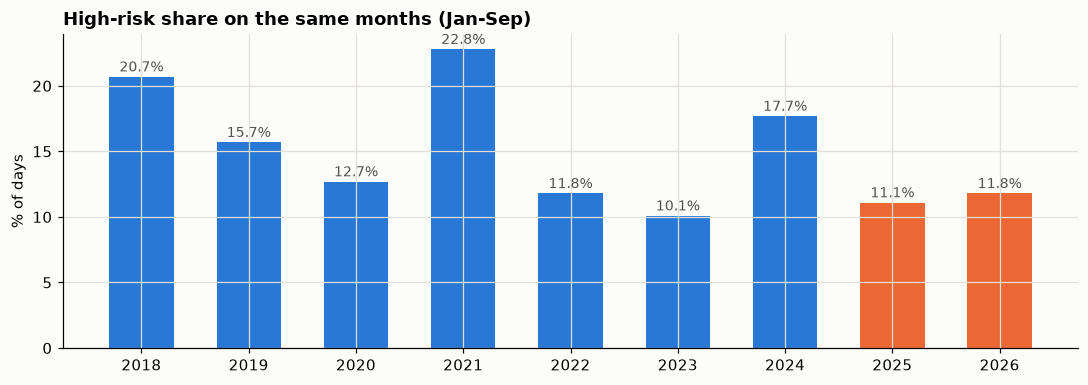

In [3]:
lab = np.where(known, (df[PM] >= THRESH).astype(float), np.nan)
assert np.allclose(lab, df.high_risk, equal_nan=True), "high_risk does not follow the rule"
print(f"high_risk = 1 on {int(df.high_risk.sum())} of {int(known.sum())} days ({100*df.high_risk.mean():.1f}%)")

d = df.assign(year=df.date.dt.year, month=df.date.dt.month)
like = pd.DataFrame({"all months with data": d.groupby("year").high_risk.mean().mul(100).round(1),
                     "Jan-Sep only": d[d.month <= 9].groupby("year").high_risk.mean().mul(100).round(1)})
display(like.T)
r = like.loc[2018:2024, "Jan-Sep only"]
print(f"2026 has data for Jan-Sep only. On Jan-Sep, 2026 = {like.loc[2026, 'Jan-Sep only']}% "
      f"vs {r.min()}-{r.max()}% in 2018-24, so its low yearly share is a calendar effect.")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(like.index, like["Jan-Sep only"], color=[BLUE if y <= 2024 else ORANGE for y in like.index], width=0.6)
for x, v in like["Jan-Sep only"].items():
    ax.text(x, v + 0.4, f"{v:.1f}%", ha="center", fontsize=9, color=INK2)
ax.set_title("High-risk share on the same months (Jan-Sep)"); ax.set_ylabel("% of days"); ax.set_xticks(like.index)
fig.tight_layout(); save(fig, "P01_high_risk_share_jan_sep")

## 2. Gaps (inputs only)

`pm25_input` is the target with the last observed reading carried forward for **at most 2 days**, from the past only. `input_age_days` says how old it is (0 = observed that day) and `input_filled` marks filled days. The target and the label are never filled.

131 gaps cover 272 days; 112 gaps are 1-2 days long.


gap length (days),1,2,3,4,6,7,9,12,31,32
gaps,96,16,8,4,1,2,1,1,1,1


Longest gaps:


,start,end,days
0,2019-02-15,2019-03-18,32
1,2023-02-16,2023-03-18,31
2,2023-02-02,2023-02-13,12



166 of 272 missing days get a carried-forward input; 106 days have no usable input.


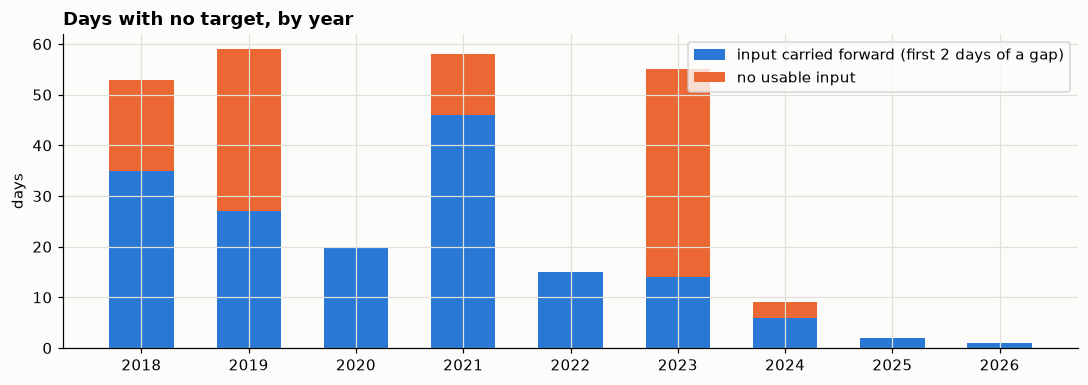

In [4]:
series = df[["date", PM, "target_source", "high_risk"]].copy()
series["missing"] = series[PM].isna().astype(int)
series["high_risk"] = series["high_risk"].astype("Int64")
series = series[["date", PM, "target_source", "missing", "high_risk"]]

miss = series.missing.astype(bool)
runs = (series.assign(run=(miss != miss.shift()).cumsum())[miss]
        .groupby("run").agg(start=("date", "min"), end=("date", "max"), days=("date", "size")))
gap_table = runs.days.value_counts().sort_index().rename_axis("gap length (days)").rename("gaps").to_frame()
print(f"{len(runs)} gaps cover {int(miss.sum())} days; {int((runs.days <= 2).sum())} gaps are 1-2 days long.")
display(gap_table.T)
print("Longest gaps:"); display(runs.sort_values("days", ascending=False).head(3).reset_index(drop=True))

inp = series.set_index("date")[PM]
last_obs = pd.Series(inp.index.where(inp.notna()), index=inp.index).ffill()
pm25_input = inp.ffill(limit=FFILL_LIMIT)
age = (inp.index.to_series() - last_obs).dt.days.where(pm25_input.notna())

ts = pd.DataFrame({"date": inp.index, PM: inp.values, "pm25_input": pm25_input.values, "input_age_days": age.values})
ts["input_filled"] = (ts.input_age_days > 0).astype(int)

# Guards: the target is never filled, inputs only look back, never more than 2 days
assert ts.loc[ts[PM].notna(), "pm25_input"].equals(ts.loc[ts[PM].notna(), PM])
assert ts.input_age_days.dropna().between(0, FFILL_LIMIT).all()
print(f"\n{int(ts.input_filled.sum())} of {int(miss.sum())} missing days get a carried-forward input; "
      f"{int(ts.pm25_input.isna().sum())} days have no usable input.")

by_year = ts.assign(year=ts.date.dt.year).groupby("year").agg(
    filled=("input_filled", "sum"), unfilled=("pm25_input", lambda s: s.isna().sum()))
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_year.index, by_year.filled, color=BLUE, width=0.6, label="input carried forward (first 2 days of a gap)")
ax.bar(by_year.index, by_year.unfilled, bottom=by_year.filled, color=ORANGE, width=0.6, label="no usable input")
ax.set_title("Days with no target, by year"); ax.set_ylabel("days"); ax.set_xticks(by_year.index); ax.legend()
fig.tight_layout(); save(fig, "P02_missing_days_by_year")

## 3. Log transform

Checks on 2018–2024: is raw PM2.5 skewed, and does its spread grow with its level? Box-Cox estimates the best power transform (λ = 0 is the log).

,skewness,"corr(monthly mean, monthly SD)"
raw PM2.5,1.53,0.98
log PM2.5,-0.06,-0.15


Box-Cox lambda = 0.031 (0 is exactly the log).


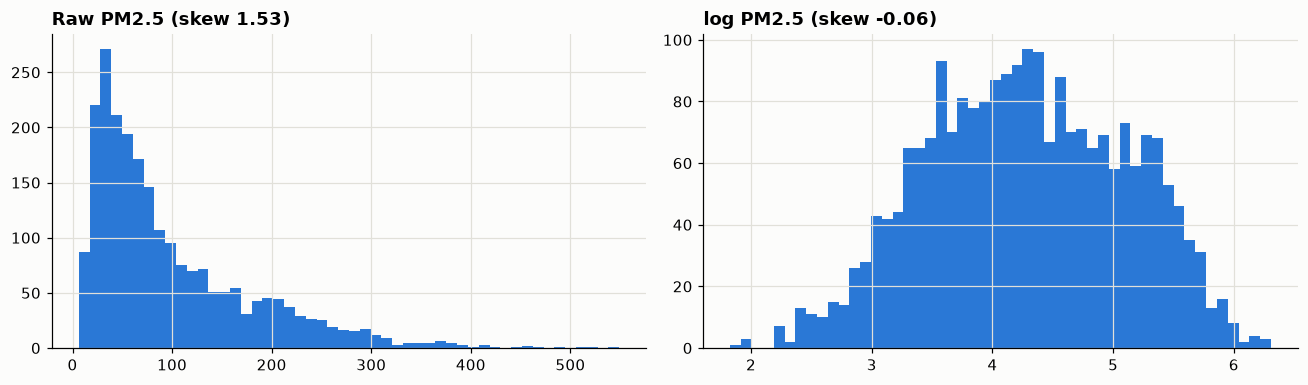

In [5]:
s = df.set_index("date")[PM]
tr = s[:TRAIN_END].dropna()
bc_lambda = stats.boxcox(tr.values)[1]
mon = pd.DataFrame({"raw_mean": tr.groupby(tr.index.month).mean(), "raw_sd": tr.groupby(tr.index.month).std(),
                    "log_mean": np.log(tr).groupby(tr.index.month).mean(), "log_sd": np.log(tr).groupby(tr.index.month).std()})
r_raw, r_log = mon.raw_mean.corr(mon.raw_sd), mon.log_mean.corr(mon.log_sd)
display(pd.DataFrame({"skewness": [tr.skew(), np.log(tr).skew()],
                      "corr(monthly mean, monthly SD)": [r_raw, r_log]},
                     index=["raw PM2.5", "log PM2.5"]).round(2))
print(f"Box-Cox lambda = {bc_lambda:.3f} (0 is exactly the log).")

ts["log_pm25"] = np.log(ts[PM])
ts["log_pm25_input"] = np.log(ts["pm25_input"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(tr, bins=50, color=BLUE); axes[0].set_title(f"Raw PM2.5 (skew {tr.skew():.2f})")
axes[1].hist(np.log(tr), bins=50, color=BLUE); axes[1].set_title(f"log PM2.5 (skew {np.log(tr).skew():.2f})")
fig.tight_layout(); save(fig, "P03_log_transform")

## 4. Lags 1–7

Built from `pm25_input` (equal to `pm25_target` except on carried-forward days), never from `pm25_mean`. Each lag only shifts values forward in time, so it uses past data only.

In [6]:
for k in range(1, 8):
    ts[f"pm25_input_lag{k}"] = ts["pm25_input"].shift(k)

# Guard: lag k on day t equals pm25_input on day t-k
for k in range(1, 8):
    assert ts[f"pm25_input_lag{k}"].iloc[k:].reset_index(drop=True).equals(
        ts["pm25_input"].iloc[:-k].reset_index(drop=True))
print("Lags 1-7 built from pm25_input; each one checked against the input k days earlier.")
display(ts[["date", "pm25_input", "pm25_input_lag1", "pm25_input_lag2", "pm25_input_lag7"]].iloc[5:12])

Lags 1-7 built from pm25_input; each one checked against the input k days earlier.


,date,pm25_input,pm25_input_lag1,pm25_input_lag2,pm25_input_lag7
5,2018-01-06,274.0,289.0,243.0,NaN
6,2018-01-07,235.0,274.0,289.0,NaN
7,2018-01-08,169.0,235.0,274.0,370.0
8,2018-01-09,169.0,169.0,235.0,383.0
9,2018-01-10,189.0,169.0,169.0,306.0
10,2018-01-11,180.0,189.0,169.0,243.0
11,2018-01-12,196.0,180.0,189.0,289.0


## 5. Consistency check: is the city mean one series?

Phase 1 built several features from `pm25_mean` (the city mean). They are only comparable over time if the city mean is made of the same stations every year.

target_source,reference,city_fallback,missing,median_stations_in_city_mean,pct_city_mean_equals_target,median_ratio_city_mean_to_target,pct_disagree_on_alert
year,,,,,,,
2018,287,25,53,1.0,54.2,1.000,6.4
2019,298,8,59,7.0,41.8,1.000,1.6
2020,345,1,20,17.0,7.8,1.030,4.6
2021,306,1,58,1.0,48.5,1.000,3.9
2022,324,26,15,1.0,57.4,1.000,2.9
2023,310,0,55,1.0,100.0,1.000,0.0
2024,357,0,9,1.0,100.0,1.000,0.0
2025,352,11,2,31.0,18.2,1.087,1.7
2026,257,15,1,31.0,15.1,1.040,2.2


,days,% pm25_mean_lag1 identical to target lag1,median ratio
per,,,
2018-24,2287.0,58.6,1.000
2025-26,636.0,17.0,1.061


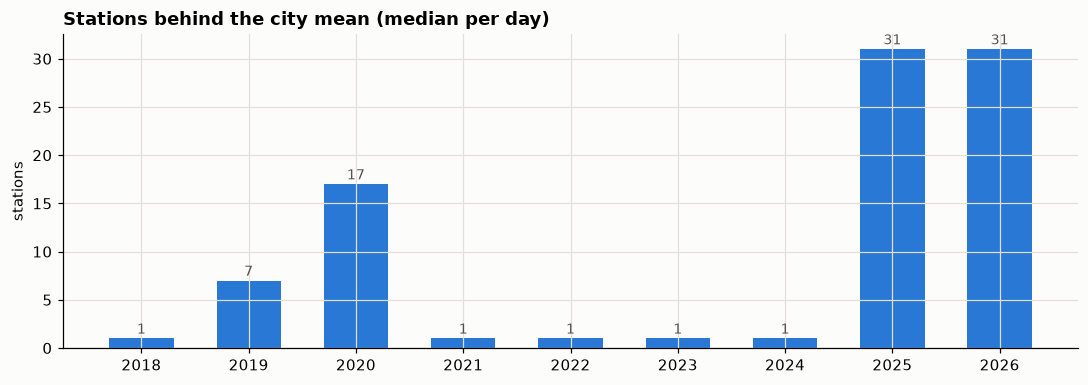

Conclusion: ~1 station until 2024, ~31 from 2025, so the city mean is not one series. Build lags from pm25_target.


In [7]:
both = d[d[PM].notna() & d.pm25_mean.notna()]
cons = pd.crosstab(d.year, d.target_source)[["reference", "city_fallback", "missing"]]
cons["median_stations_in_city_mean"] = d.groupby("year").pm25_n_stations.median()
cons["pct_city_mean_equals_target"] = (100 * both.assign(eq=np.isclose(both.pm25_mean, both[PM]))
                                       .groupby("year").eq.mean()).round(1)
cons["median_ratio_city_mean_to_target"] = (both.pm25_mean / both[PM]).groupby(both.year).median().round(3)
cons["pct_disagree_on_alert"] = (100 * ((both.pm25_mean >= THRESH) != (both[PM] >= THRESH))
                                 .groupby(both.year).mean()).round(1)
display(cons)

lag_t = df[PM].shift(1)
x = df.assign(lag_t=lag_t, per=np.where(df.date <= TRAIN_END, "2018-24", "2025-26")).dropna(subset=["pm25_mean_lag1", "lag_t"])
drift = x.groupby("per", sort=False).apply(lambda g: pd.Series({
    "days": len(g),
    "% pm25_mean_lag1 identical to target lag1": round(100 * np.isclose(g.pm25_mean_lag1, g.lag_t).mean(), 1),
    "median ratio": round((g.pm25_mean_lag1 / g.lag_t).median(), 3)}))
display(drift)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(cons.index, cons.median_stations_in_city_mean, color=BLUE, width=0.6)
for xv, v in cons.median_stations_in_city_mean.items():
    ax.text(xv, v + 0.5, f"{v:.0f}", ha="center", fontsize=9, color=INK2)
ax.set_title("Stations behind the city mean (median per day)"); ax.set_ylabel("stations"); ax.set_xticks(cons.index)
fig.tight_layout(); save(fig, "P04_stations_in_city_mean")
print("Conclusion: ~1 station until 2024, ~31 from 2025, so the city mean is not one series. Build lags from pm25_target.")

## 6. Leak audit of Phase 1 features

Each Phase 1 pollution feature is rebuilt from its definition, checked against the Phase 1 column, and tagged by what it is built from and whether it uses pollution from the day being predicted.

In [8]:
pm, aqi, pm10 = df.pm25_mean, df.aqi_pm25, df.pm10_mean
recipes = {
    "aqi_pm25_lag1":        (aqi.shift(1), "pm25_target (as AQI)", "no"),
    "aqi_pm25_lag2":        (aqi.shift(2), "pm25_target (as AQI)", "no"),
    "aqi_pm25_lag3":        (aqi.shift(3), "pm25_target (as AQI)", "no"),
    "prev_high_risk":       (df.high_risk.shift(1), "pm25_target (label)", "no"),
    "high_risk_past3d":     (df.high_risk.shift(1).rolling(3, min_periods=1).sum(), "pm25_target (label)", "no"),
    "high_risk_past7d":     (df.high_risk.shift(1).rolling(7, min_periods=1).sum(), "pm25_target (label)", "no"),
    "pm25_mean_lag1":       (pm.shift(1), "pm25_mean (city mean)", "no"),
    "pm25_mean_lag2":       (pm.shift(2), "pm25_mean (city mean)", "no"),
    "pm25_mean_lag3":       (pm.shift(3), "pm25_mean (city mean)", "no"),
    "pm25_mean_roll3_mean": (pm.shift(1).rolling(3, min_periods=1).mean(), "pm25_mean (city mean)", "no"),
    "pm25_mean_roll3_std":  (pm.shift(1).rolling(3, min_periods=1).std(), "pm25_mean (city mean)", "no"),
    "pm25_mean_roll7_mean": (pm.shift(1).rolling(7, min_periods=1).mean(), "pm25_mean (city mean)", "no"),
    "pm25_mean_roll7_std":  (pm.shift(1).rolling(7, min_periods=1).std(), "pm25_mean (city mean)", "no"),
    "pm25_mean_change":     (pm - pm.shift(1), "pm25_mean (city mean)", "YES (day t minus day t-1)"),
    "pm10_mean":            (pm10, "pm10_mean", "YES (day t)"),
    "pm10_mean_lag1":       (pm10.shift(1), "pm10_mean", "no"),
    "pm10_mean_lag2":       (pm10.shift(2), "pm10_mean", "no"),
    "pm10_mean_lag3":       (pm10.shift(3), "pm10_mean", "no"),
    "pm25_pm10_ratio":      (np.where(pm10.notna() & (pm10 > 0), pm / pm10, np.nan), "pm25_mean / pm10_mean", "YES (both day t)"),
    "pm10_available":       (pm10.notna().astype(int), "pm10_mean", "YES (day t)"),
}
test_rows = (df.date >= TEST_START) & df.high_risk.notna()
rows = []
for feat, (rec, base, same_day) in recipes.items():
    rec = pd.Series(rec, index=df.index, dtype=float)
    t = df.loc[test_rows, [feat, "high_risk"]].dropna()
    auc = roc_auc_score(t.high_risk, t[feat]) if t[feat].nunique() > 1 else np.nan
    rows.append({"feature": feat, "built_from": base, "uses_pollution_from_day_t": same_day,
                 "recipe_verified": np.allclose(rec, df[feat].astype(float), equal_nan=True),
                 "auc_alone_2025_26": round(max(auc, 1 - auc), 3)})
audit = pd.DataFrame(rows)
assert audit.recipe_verified.all()
audit["verdict"] = np.select(
    [audit.uses_pollution_from_day_t.str.startswith("YES"), audit.built_from.str.startswith("pm25_mean")],
    ["LEAK: drop", "Inconsistent basis: rebuild from pm25_target"], default="OK")
display(audit)

t = df.loc[test_rows].assign(today=lambda g: g.pm25_mean_lag1 + g.pm25_mean_change).dropna(subset=["today"])
print(f"pm25_mean_lag1 + pm25_mean_change = today's city mean. On {len(t)} days of 2025-26 it separates "
      f"high-risk days with AUC {roc_auc_score(t.high_risk, t.today):.3f}.")
print(f"Leaks to drop: {audit.verdict.str.startswith('LEAK').sum()} | "
      f"built from pm25_mean, to rebuild: {audit.verdict.str.startswith('Inconsistent').sum()}")

,feature,built_from,uses_pollution_from_day_t,recipe_verified,auc_alone_2025_26,verdict
0,aqi_pm25_lag1,pm25_target (as AQI),no,True,0.982,OK
1,aqi_pm25_lag2,pm25_target (as AQI),no,True,0.966,OK
2,aqi_pm25_lag3,pm25_target (as AQI),no,True,0.958,OK
3,prev_high_risk,pm25_target (label),no,True,0.920,OK
4,high_risk_past3d,pm25_target (label),no,True,0.946,OK
5,high_risk_past7d,pm25_target (label),no,True,0.966,OK
6,pm25_mean_lag1,pm25_mean (city mean),no,True,0.980,Inconsistent basis: rebuild from pm25_target
7,pm25_mean_lag2,pm25_mean (city mean),no,True,0.965,Inconsistent basis: rebuild from pm25_target
8,pm25_mean_lag3,pm25_mean (city mean),no,True,0.958,Inconsistent basis: rebuild from pm25_target
9,pm25_mean_roll3_mean,pm25_mean (city mean),no,True,0.977,Inconsistent basis: rebuild from pm25_target


pm25_mean_lag1 + pm25_mean_change = today's city mean. On 634 days of 2025-26 it separates high-risk days with AUC 0.998.
Leaks to drop: 4 | built from pm25_mean, to rebuild: 7


## 7. Inputs left out

* **PM10:** checked below; too much of it is missing.
* **Weather:** the merged file has weather columns (temperature, humidity, wind, rain, pressure, cloud), but they are not part of M2's input files.

In [9]:
pm10_avail = merged.groupby(merged.date.dt.year).pm10_mean.apply(lambda s: round(100 * s.notna().mean(), 1))
display(pm10_avail.rename("% of days with PM10").to_frame().T)
print(f"PM10 is missing on every day of 2023 and 2024, and available on only "
      f"{100*merged.pm10_mean.notna().mean():.1f}% of all days, so it is not used as an input.")
weather = ["temp_mean", "humidity_mean", "wind_speed_mean", "precip_sum", "pressure_mean", "cloud_mean"]
print("Weather columns present in the merged file (not used here):", [c for c in weather if c in merged.columns])

date,2018,2019,2020,2021,2022,2023,2024,2025,2026
% of days with PM10,47.9,51.2,87.4,43.8,47.9,0.0,0.0,84.4,90.1


PM10 is missing on every day of 2023 and 2024, and available on only 49.2% of all days, so it is not used as an input.
Weather columns present in the merged file (not used here): ['temp_mean', 'humidity_mean', 'wind_speed_mean', 'precip_sum', 'pressure_mean', 'cloud_mean']


## 8. Write the outputs

In [10]:
cols = ["date", PM, "pm25_input", "input_age_days", "input_filled", "log_pm25", "log_pm25_input"] + \
       [f"pm25_input_lag{k}" for k in range(1, 8)]
series.to_csv(OUT / "p2_series.csv", index=False, date_format=DATE_FMT)
ts[cols].to_csv(OUT / "p2_ts_inputs.csv", index=False, date_format=DATE_FMT)
cons.to_csv(OUT / "p2_consistency_by_year.csv")
audit.to_csv(OUT / "p2_phase1_feature_audit.csv", index=False)

chk = pd.read_csv(OUT / "p2_series.csv", parse_dates=["date"])
assert list(chk.columns) == ["date", "pm25_target", "target_source", "missing", "high_risk"]
assert chk.pm25_target.isna().sum() == chk.missing.sum()
files = ["p2_series.csv", "p2_ts_inputs.csv", "p2_consistency_by_year.csv", "p2_phase1_feature_audit.csv"]
display(pd.DataFrame([{"file": f, "rows": len(pd.read_csv(OUT / f)), "columns": pd.read_csv(OUT / f).shape[1]} for f in files]))
print("All checks passed. Outputs in", OUT.resolve())

,file,rows,columns
0,p2_series.csv,3195,5
1,p2_ts_inputs.csv,3195,14
2,p2_consistency_by_year.csv,9,8
3,p2_phase1_feature_audit.csv,20,6


All checks passed. Outputs in /private/tmp/claude-501/-Users-akilan-Library-Application-Support-Claude-scratch-workspaces-9e19f909-7ff3-43fe-a56e-f80f1eabf7af-21db9c52-28f7-4454-9c72-372adea3e452-scratch-2026-10-02-c41354/25faecc6-b309-4566-bb2c-ea622f549ac4/scratchpad/repo/notebooks/outputs


## Summary

* **Series:** `pm25_target` (reference station on 2,836 days, city mean with ≥ 10 stations on 87, missing on 272). `pm25_mean` is not used.
* **Label:** `high_risk` on 792 of 2,923 days (27.1%); 2026's low share is a calendar effect.
* **Gaps:** inputs carried forward ≤ 2 days (166 of 272 missing days recovered); the target is never filled.
* **Log transform:** removes the skew and the link between level and spread; Box-Cox λ ≈ 0.
* **Lags 1–7:** built from `pm25_input`.
* **Consistency:** the city mean goes from ~1 to ~31 stations in 2025; 7 Phase 1 features built from it must be rebuilt.
* **Leak audit:** 4 Phase 1 features use same-day pollution and are dropped.
* **Left out:** PM10 (missing in 2023–24) and weather.